# Wizualizacja danych w `matplotlib` i `seaborn`

## Wykres liniowy

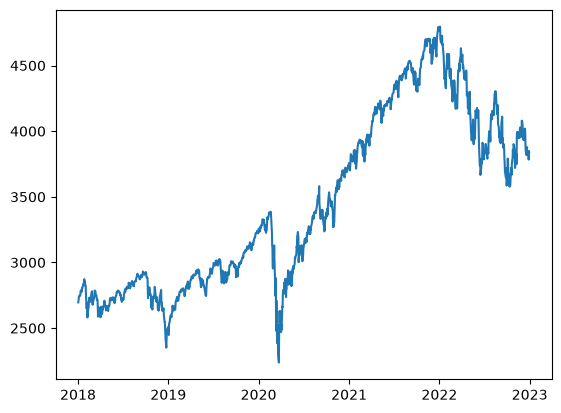

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("SP500.csv", parse_dates=True, index_col="Date")

plt.plot(df.index, df.Close) # Wskazówka: jeśli jedną z osi są daty, warto zapewnić typ danych datetime

## Dodawanie wielu wykresów, tytułów, legendy

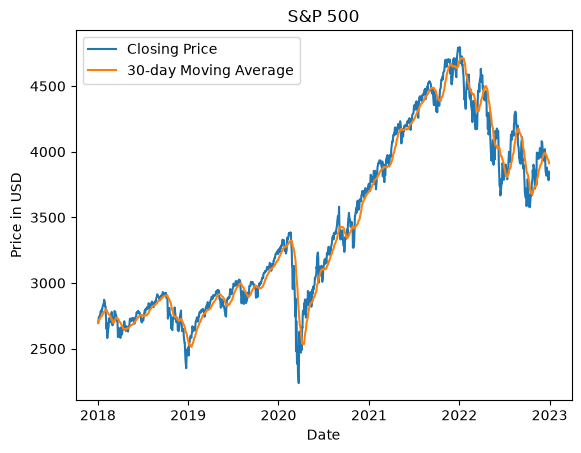

In [20]:
plt.plot(df.index, df.Close, label="Closing Price")
plt.plot(df.index, df.Close.rolling('30D').mean(), label="30-day Moving Average")

plt.title("S&P 500")
plt.xlabel("Date")
plt.ylabel("Price in USD")
plt.legend()

## Histogram

Text(0.5, 1.0, 'Histogram of Sepal Width')

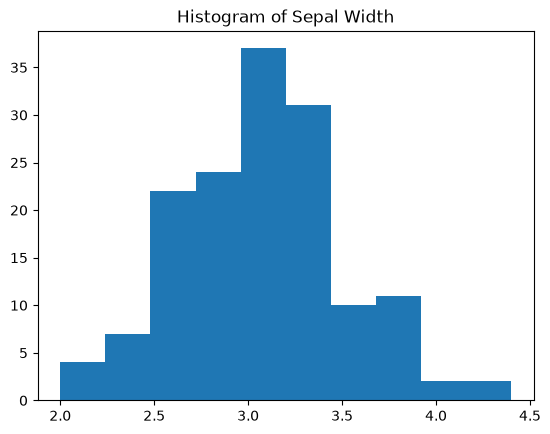

In [21]:
iris = pd.read_csv("iris.csv")

plt.hist(iris.sepal_width, bins=10)
plt.title("Histogram of Sepal Width")

## Wykres pudełkowy

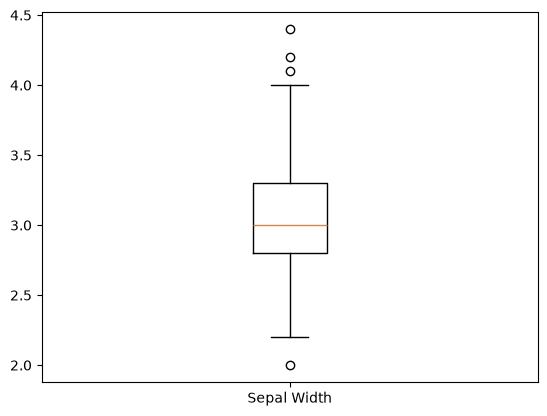

In [22]:
plt.boxplot(iris.sepal_width, tick_labels=["Sepal Width"]);

Aby stworzyć kilka wykresów pudełkowych można podać listę zawierającą kilka wektorów z danymi numerycznymi, lub `DataFrame`. Parametr `vert` pozwala rysować wykres w pionie lub poziomie.

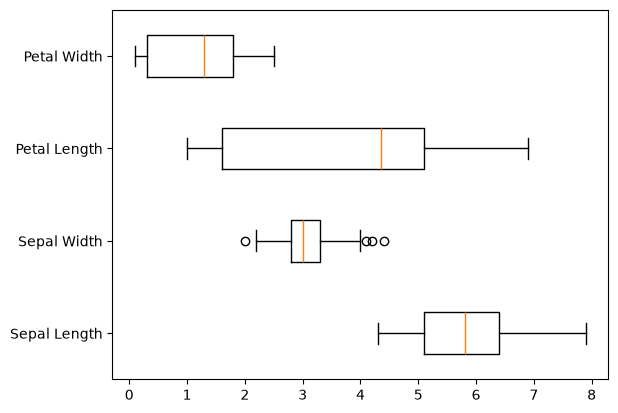

In [23]:
iris_numeric = iris.drop("variety", axis=1)
tick_labels = iris_numeric.columns.str.replace("_", " ").str.title()
plt.boxplot(iris_numeric, tick_labels=tick_labels, orientation="horizontal");

## Wykres słupkowy
Wykres słupkowy pionowy tworzymy metodą `plt.bar()`, a poziomy `plt.barh()`. Na wykresie możemy zaznaczyć błędy pomiaru podając `yerr`, lub `xerr` - w tym przypadku zaznaczam 2SE (przybliżona szerokość 95% przedziału ufności). W poniższym przykładzie ilustruję też dodawanie napisów metodą `plt.annotate()`.

<>:11: SyntaxWarning: invalid escape sequence '\p'
<>:11: SyntaxWarning: invalid escape sequence '\p'
C:\Users\kubag\AppData\Local\Temp\ipykernel_24760\3912837975.py:11: SyntaxWarning: invalid escape sequence '\p'
  plt.annotate(text=f"${mu:.2f} \pm {SE[col]:.2f}$",


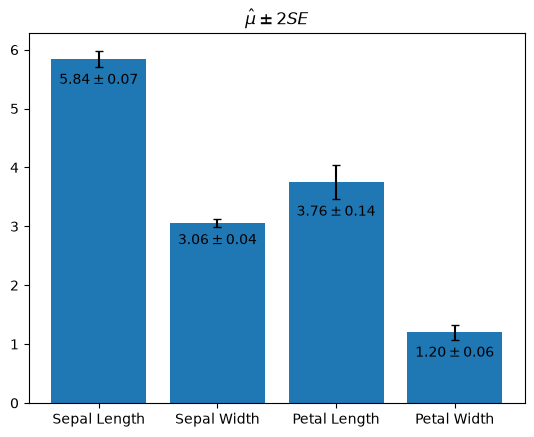

In [24]:
SE = iris_numeric.apply(lambda x: x.std()/(x.size**0.5), axis=0) # SE = sigma/sqrt(n)

plt.bar(iris_numeric.columns, iris_numeric.mean(), yerr=2*SE, capsize=3)

plt.title(r"$\hat{\mu} \pm 2SE$")
tick_labels = iris_numeric.columns.str.replace("_", " ").str.title()
plt.xticks(ticks=iris_numeric.columns, labels=tick_labels)

for col in iris_numeric:
    mu = iris_numeric[col].mean()
    plt.annotate(text=f"${mu:.2f} \pm {SE[col]:.2f}$", 
                 xy=(col, mu-2*SE[col]-0.3), 
                 horizontalalignment='center')

## Wykres punktowy

Text(0, 0.5, 'Petal Width')

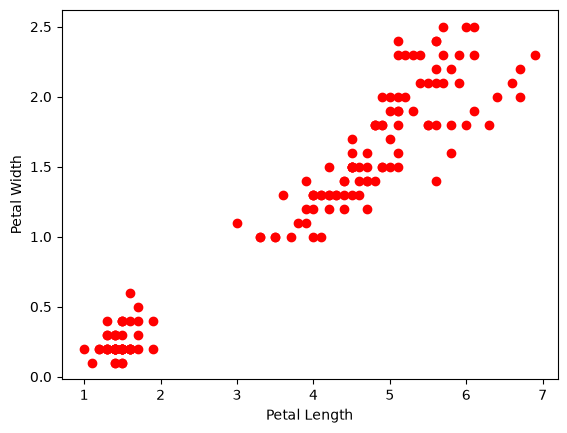

In [25]:
plt.scatter(x="petal_length", y="petal_width", c="r", data=iris)
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

## Dodawanie koloru do wykresu
W przykładzie powyżej ustawiliśmy czerwony kolor punktów podając `c="r"`. Możliwe jest także podanie wektora zawierającego kolor każdego punktu.

Text(0, 0.5, 'Petal Width')

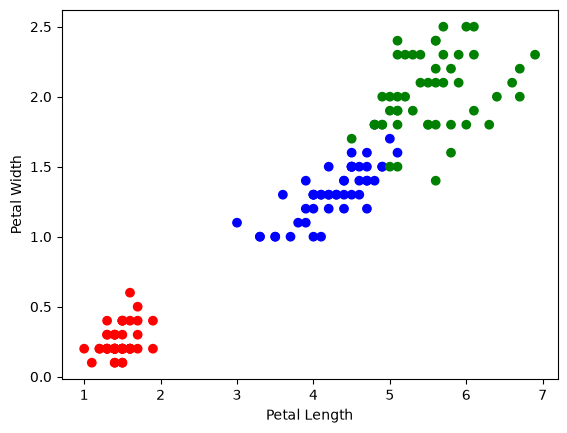

In [26]:
color = iris.variety.map({"Setosa": "r", "Versicolor": "b", "Virginica": "g"})

plt.scatter(x="petal_length", y="petal_width", c=color, data=iris)
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

Alternatywną metodą jest podanie kodów 0, 1, 2, ..., które zostaną automatycznie mapowane na kolory. Takie kody można wygenerować np. metodą `factorize()`. Opcjonalnie można podać mapę kolorów `cmap` ([więcej o mapach kolorów](https://matplotlib.org/stable/tutorials/colors/colormaps.html)).

Text(0, 0.5, 'Petal Width')

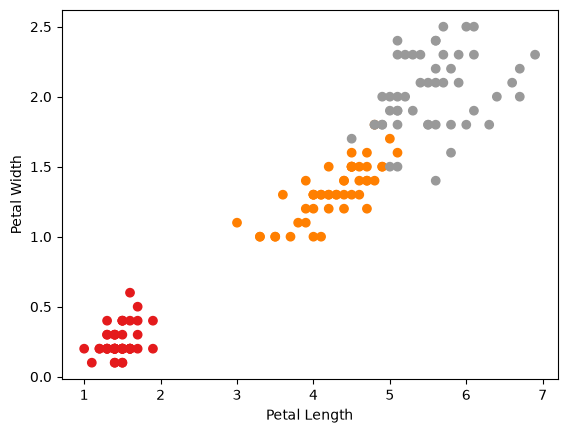

In [27]:
codes, uniques = iris.variety.factorize()
plt.scatter(x="petal_length", y="petal_width", c=codes, cmap='Set1', data=iris)
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

Mapowanie kolumny kategorycznej na kolor jest dużo prostsze w Seaborn:

Text(0, 0.5, 'Petal Width')

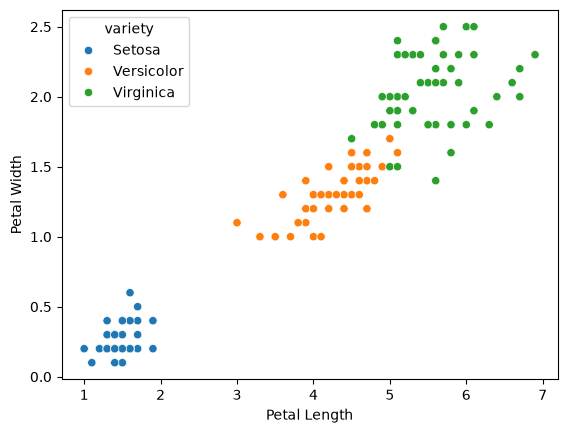

In [28]:
import seaborn as sns
sns.scatterplot(x="petal_length", y="petal_width", hue="variety", data=iris)
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

Działa to też np. w `sns.boxplot()` (dane trzeba przedtem wstępnie przekształcić w format 'długi').

<Axes: xlabel='Measurement', ylabel='Value'>

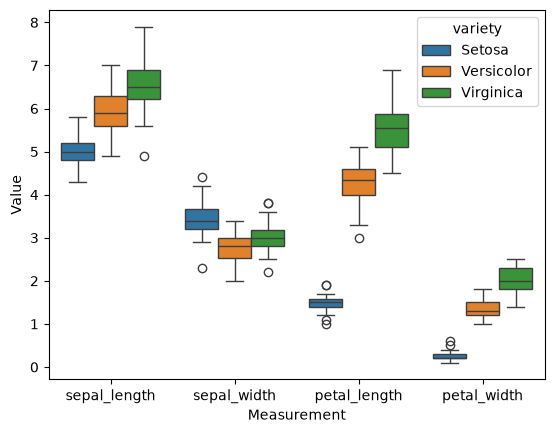

In [29]:
iris_long = iris.melt(id_vars="variety", 
                      value_vars=iris.columns[:-1], 
                      var_name="Measurement", 
                      value_name="Value")
sns.boxplot(x=iris_long.Measurement, 
            y=iris_long.Value, 
            hue=iris_long.variety, 
            orient='v')

## `subplots()`
Aby tworzyć wiele wykresów na jednej figurze wykorzystujemy metodę `plt.subplots()` podając jako argumenty liczbę wierszy i kolumn. Metoda zwraca obiekt `Figure` i `np.array` zawierający odpowiednie osie (`Axes`), na których możemy tworzyć wykresy tymi samymi metodami, które są dostępne bezpośrednio w `plt`. Często metoda `subplots()` jest przydatna nawet jeśli tworzymy tylko jeden wykres, ponieważ daje kontrolę nad parametrami figury (możemy np. ustawić jej rozmiar).

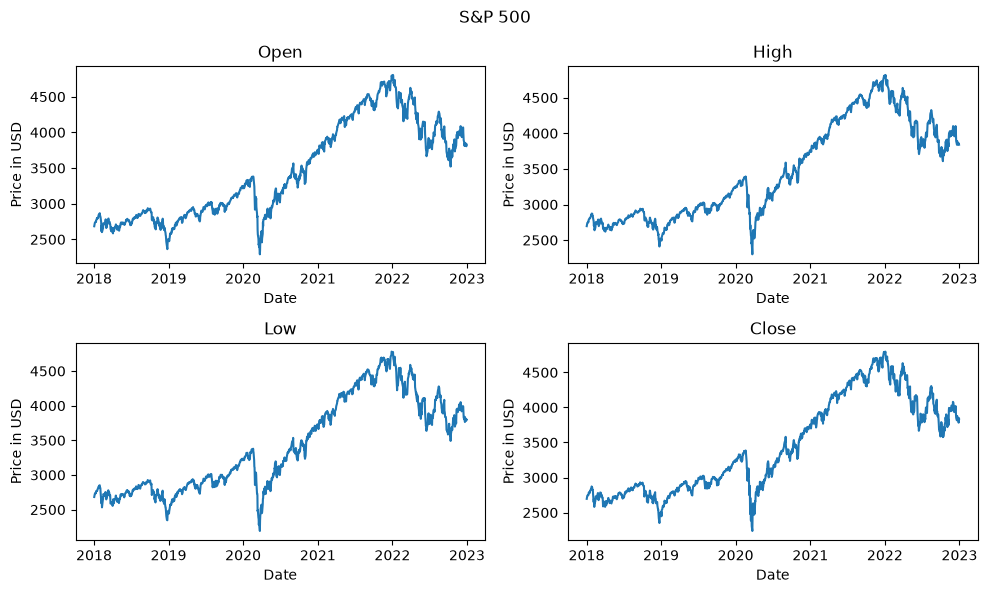

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6)) # Rozmiar w calach

for col, ax in zip(df.columns[:4], axes.ravel()):
    ax.plot(df.index, df[col])
    ax.set_title(col)
    ax.set_xlabel("Date")
    ax.set_ylabel("Price in USD")

fig.suptitle("S&P 500")
fig.tight_layout() # Zapewnia miejsce na tytuły wykresów

## `pairplot()`
Bardzo przydatnym narzędziem we wstępnej eksploracji danych są wykresy par zmiennych, tzw. *pairplot* lub *scatter matrix*. 

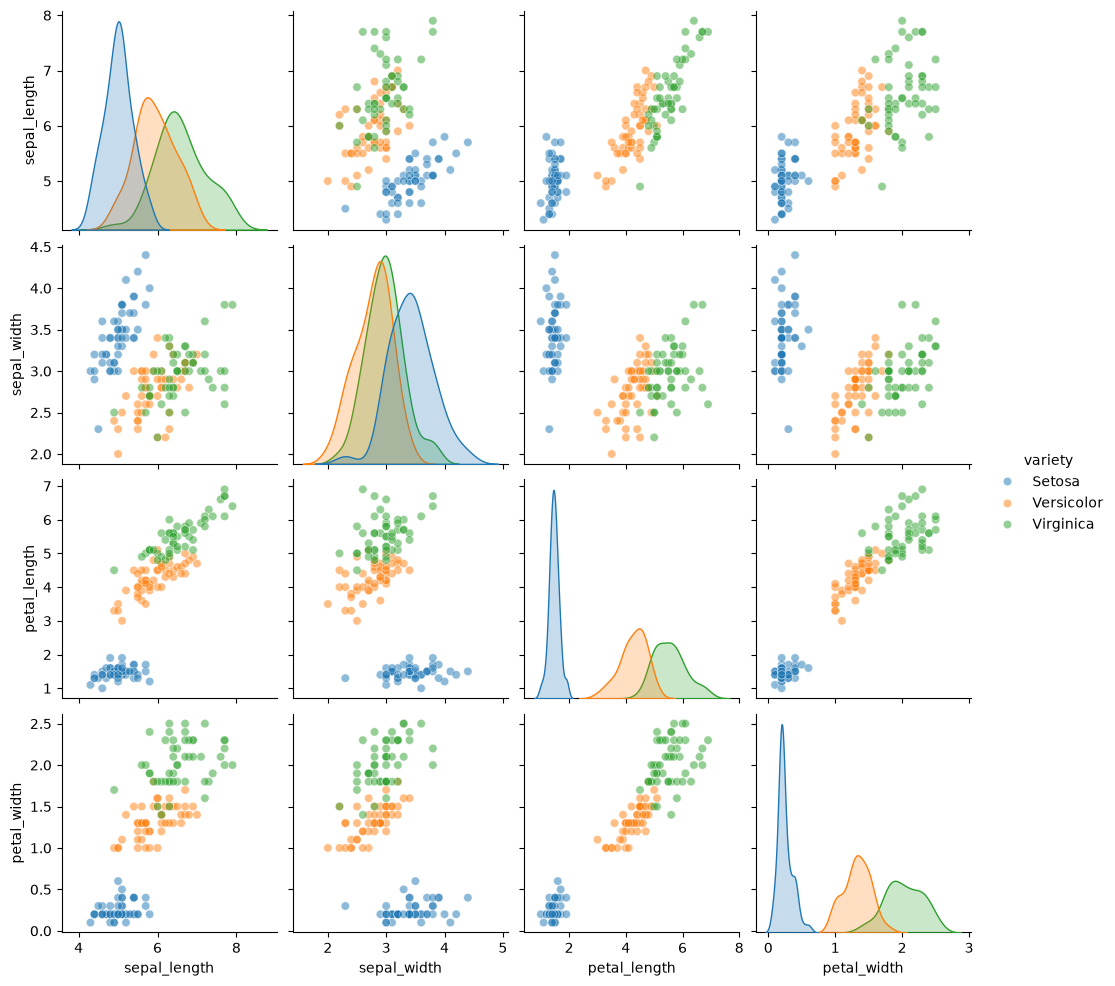

In [31]:
sns.pairplot(data=iris, hue="variety", plot_kws={'alpha': 0.5})

W niektóych przypadkach, np. kiedy mamy bardzo wiele zmiennych, wygodniej jest zwizualizować macierz korelacji. Nadaje się do tego wykres `heatmap`.

Text(0.5, 1.0, 'Correlation Matrix')

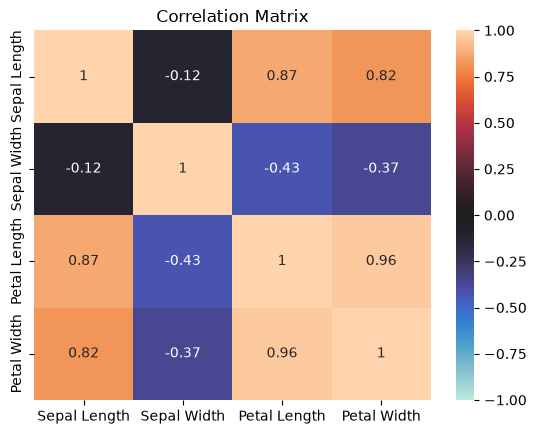

In [32]:
tick_labels = iris_numeric.columns.str.replace("_", " ").str.title()
sns.heatmap(data=iris.corr(numeric_only=True), 
            vmin=-1, 
            vmax=1, 
            annot=True, 
            center=0, 
            xticklabels=tick_labels, 
            yticklabels=tick_labels)
plt.title("Correlation Matrix")

## Zadania

### 1. Dzienne obroty S&P 500

Wczytaj plik `SP500.csv`, a następnie:
- Stwórz histogram dziennych obrotów (`Volume`). Wybierz odpowiednią liczbę koszyków parametrem `bins`. Sprawdź w [dokumentacji `hist()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html), jak stworzyć histogram gęstości.
- Rozkład dziennych obrotów wizualizuj także za pomocą wykresu pudełkowego.
- Wskazówka: bardziej czytelne będą wykresy dla dziennych obrotów w mln szt. (`Volume / 10e6`). W przypadku skalowania danych, pamiętaj o zaznaczeniu tego na wykresie (np. w opisie osi).

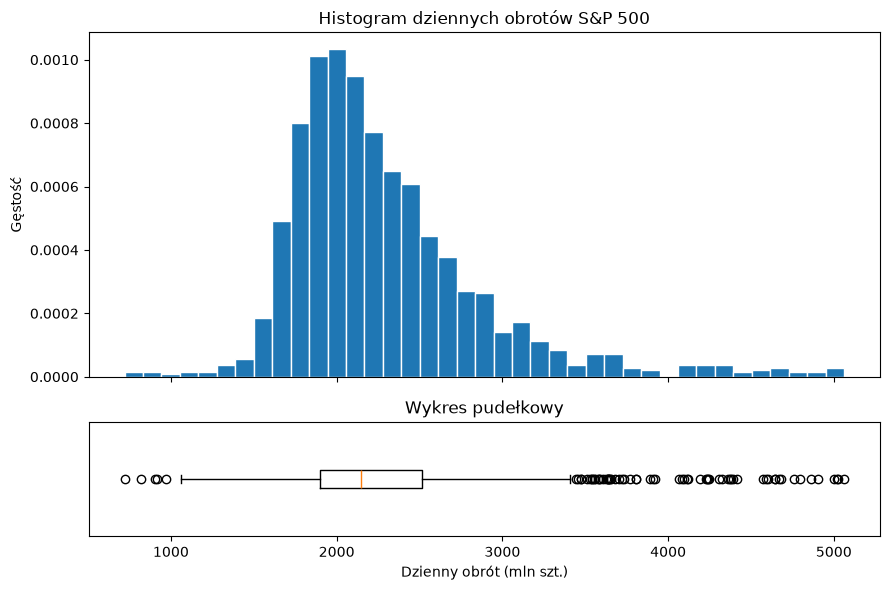

In [33]:
# 1.1 Wczytanie danych S&P 500 i przeliczenie obrotów na mln sztuk
sp500 = pd.read_csv("SP500.csv")
volume = sp500["Volume"].dropna() / 1_000_000

fig, (ax_hist, ax_box) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                                      gridspec_kw={"height_ratios": [3, 1]})
# 1.2 Histogram gęstości z automatycznym doborem koszyków
ax_hist.hist(volume, bins="fd", density=True, edgecolor="white")
ax_hist.set(title="Histogram dziennych obrotów S&P 500", ylabel="Gęstość")
# 1.3 Wykres pudełkowy obrotów
ax_box.boxplot(volume, orientation="horizontal")
ax_box.set(title="Wykres pudełkowy", xlabel="Dzienny obrót (mln szt.)", yticks=[])
fig.tight_layout()
plt.show()

### 2. Temperatury w Warszawie

Wczytaj plik `waw_weather_monthly.csv`, a następnie:
- Stwórz wykres słupkowy (`plt.bar()`) przedstawiający amplitudę średnich temperatur w każdym miesiącu (Tmax - Tmin).
- Stwórz podobny wykres, tak aby podstawą słupków była temperatura minimalna (sprawdź w [dokumentacji](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html), jak to zrobić). Ustaw odpowiedni zakres osi y (`plt.ylim()`)
- Pamiętaj o dodaniu odpowiednich opisów osi i tytułów. Aby nazwy miesięcy były czytelne, należy je obrócić (np. `plt.xticks(rotation=90)`).
- Opcjonalnie: Dodaj anotacje (`plt.annotate()`) z minimalną i maksymalną wartością temperatury pod i nad każdym słupkiem.

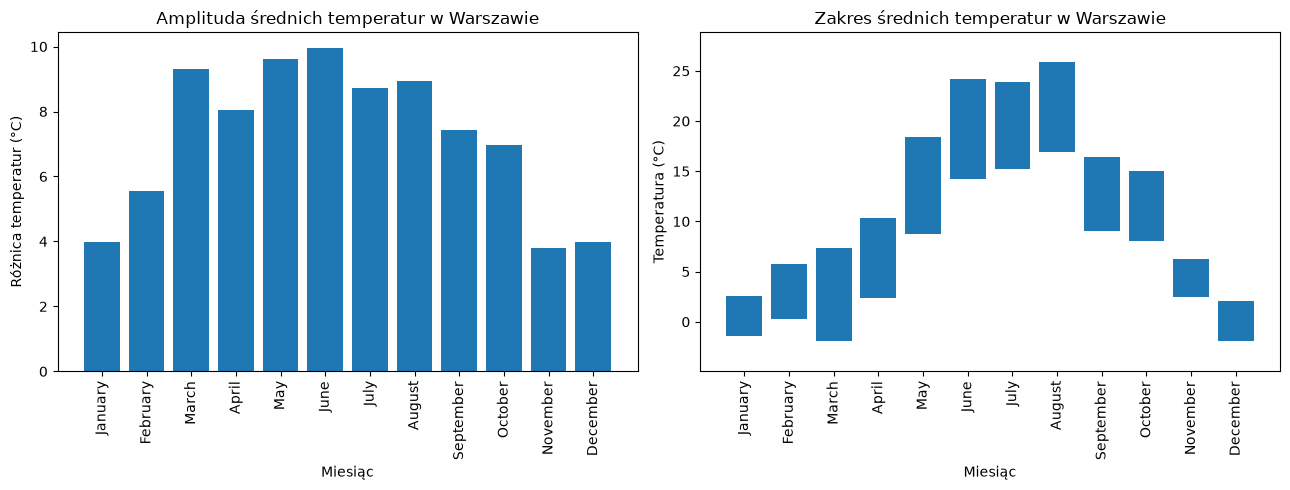

In [34]:
# 2.1 Wczytanie danych pogodowych i obliczenie Tmax − Tmin
weather = pd.read_csv("waw_weather_monthly.csv")
months = weather["time"]
t_min = weather["temperature_2m_min"]
t_max = weather["temperature_2m_max"]
amplitude = t_max - t_min

fig, (ax_amplitude, ax_range) = plt.subplots(1, 2, figsize=(13, 5))
# 2.2 Wykres amplitudy średnich temperatur
ax_amplitude.bar(months, amplitude)
ax_amplitude.set(title="Amplituda średnich temperatur w Warszawie",
                 ylabel="Różnica temperatur (°C)")
# 2.3 Wykres z podstawą w Tmin i zakresem osi obejmującym Tmin oraz Tmax
ax_range.bar(months, amplitude, bottom=t_min)
ax_range.set(title="Zakres średnich temperatur w Warszawie",
             ylabel="Temperatura (°C)", ylim=(t_min.min() - 3, t_max.max() + 3))

# 2.4 Opis osi X i obrót nazw miesięcy
for ax in (ax_amplitude, ax_range):
    ax.set_xlabel("Miesiąc")
    ax.tick_params(axis="x", labelrotation=90)

fig.tight_layout()
plt.show()

### 3. PKB i emisje CO₂ na mieszkańca

Wczytaj plik `world_bank_co2.csv`, a następnie:
- Stwórz wykres punktowy pokazujący zależność między `GDP/capita, PPP` a `CO2/capita` za pomocą `plt.scatter()`.
- Stwórz podobny wykres za pomocą `sns.scatterplot()`, tak aby kolory punktów (`hue`) odpowiadały regionom, a rozmiary (`size`) populacji (w mln).
- Wskazówka: często wykresy punktowe są czytelniejsze po odpowiednim dobraniu parametru `alpha`.

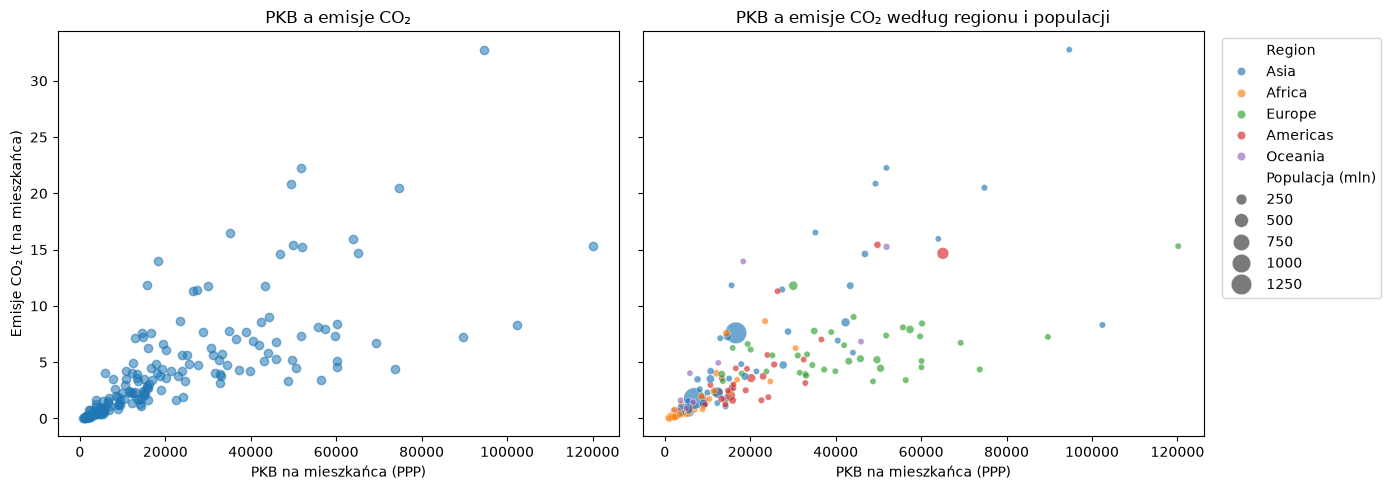

In [35]:
# 3.1 Wczytanie danych i przeliczenie populacji na miliony
co2 = pd.read_csv("world_bank_co2.csv")
co2["Populacja (mln)"] = co2["Population"] / 1_000_000
gdp = "GDP/capita, PPP"
emissions = "CO2/capita"
co2 = co2.dropna(subset=[gdp, emissions])

fig, (ax_plain, ax_regions) = plt.subplots(1, 2, figsize=(14, 5),
                                          sharex=True, sharey=True)
# 3.2 Wykres punktowy PKB i emisji za pomocą Matplotlib
ax_plain.scatter(co2[gdp], co2[emissions], alpha=0.55)
ax_plain.set_title("PKB a emisje CO₂")
# 3.3 Wykres Seaborn z kolorem według regionu i rozmiarem według populacji
sns.scatterplot(data=co2, x=gdp, y=emissions, hue="Region",
                size="Populacja (mln)", sizes=(20, 240), alpha=0.65, ax=ax_regions)
ax_regions.set_title("PKB a emisje CO₂ według regionu i populacji")
ax_regions.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

for ax in (ax_plain, ax_regions):
    ax.set_xlabel("PKB na mieszkańca (PPP)")
    ax.set_ylabel("Emisje CO₂ (t na mieszkańca)")

fig.tight_layout()
plt.show()

### 4. Wykres par dla danych Iris

Użyj `subplots()` aby manualnie stworzyć wykres par dla danych `iris` podobny do tego z przykładu powyżej. Podanie parametrów `sharex`, `sharey` pozwala współdzielić osie wykresów. Dodaj opisy do osi zewnętrznych wykresów (metodą `ax.set_title()`). Nie jest wymagane rysowanie histogramów na przekątnej. W przypadku dużego zagęszczenia punktów na wykresie warto zmniejszyć parametr `alpha`.

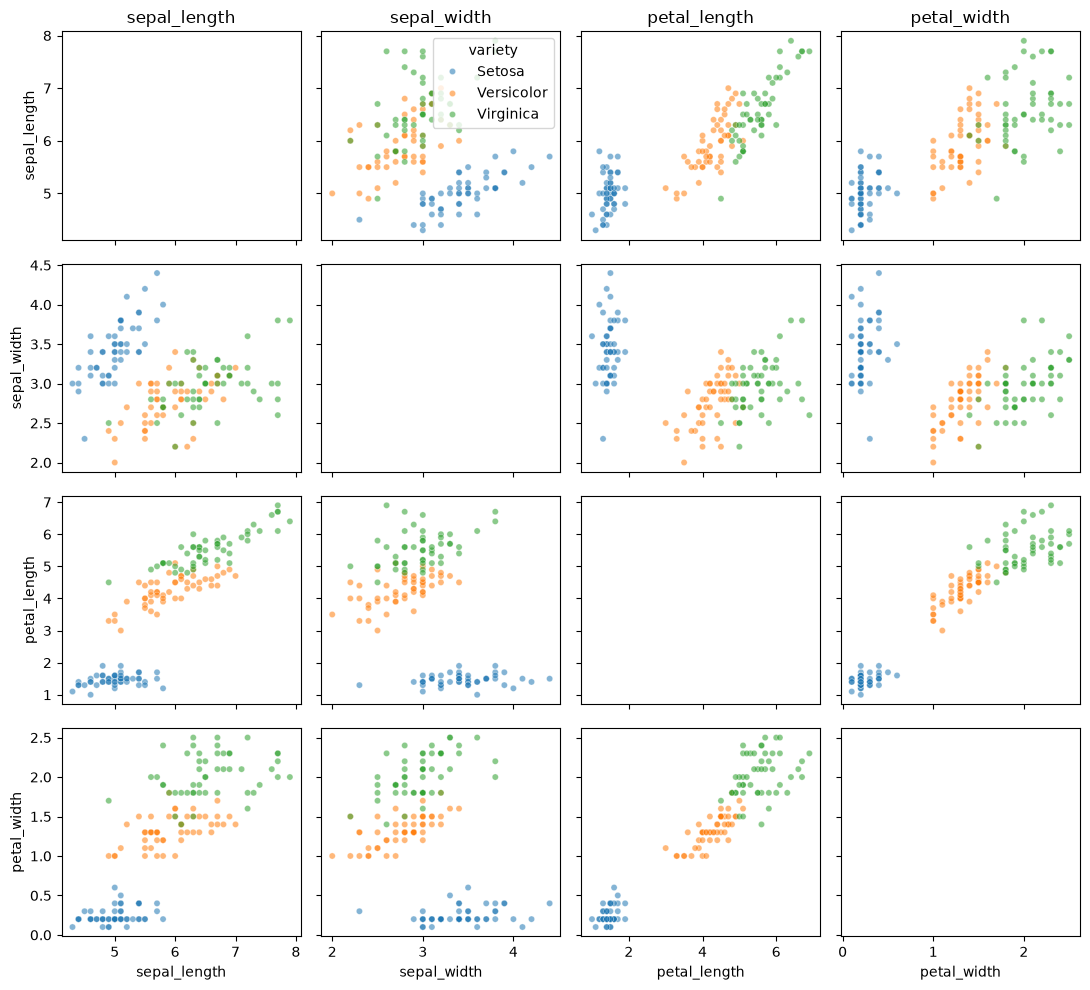

In [36]:
features = iris.columns.drop("variety")
# 4.1 Siatka Iris ze wspólnymi osiami w kolumnach i wierszach
fig, axes = plt.subplots(4, 4, figsize=(11, 10), sharex="col", sharey="row")

# 4.2 Wykresy punktowe dla par różnych cech i etykiety osi zewnętrznych
for row, y in enumerate(features):
    for col, x in enumerate(features):
        ax = axes[row, col]
        if row != col:
            sns.scatterplot(data=iris, x=x, y=y, hue="variety", ax=ax,
                            legend=(row, col) == (0, 1), alpha=0.55, s=20)
        ax.set(xlabel=x if row == 3 else "", ylabel=y if col == 0 else "")

# 4.3 Nazwy cech nad wykresami w górnym wierszu
for ax, feature in zip(axes[0], features):
    ax.set_title(feature)

fig.tight_layout()
plt.show()